# Reviewer item (2): isolated tidal-field tests

This notebook is intentionally isolated from `fdm.ipynb` and `tidal.ipynb`. It uses the same $m_a=10^{-22}$ eV, $M=10^9 M_\odot$, seed-0 initial conditions and halo snapshots, while writing all new potentials, trajectories, tables and figures below `ma1.0e-22M1.0e+09ts0.1rres512_tests/s0`.

The controls separate (i) the static time-averaged base field, (ii) a frozen fully-ramped snapshot, and (iii) the fiducial evolving field. The remaining cells test spatial resolution, temporal interpolation, absolute acceleration accuracy, and the local tidal-equation reconstruction.

In [1]:
from pathlib import Path
import sys, os, importlib
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Use the project environment when the notebook kernel was started elsewhere.
PROJECT = next((path for path in (Path.cwd(), *Path.cwd().parents)
                 if (path / 'tests.py').exists()), Path.cwd())
FIGURES_DIR = PROJECT / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
import tests as tests_module
tests_module = importlib.reload(tests_module)
from tests import (load_agama, build_static_potential, integrate_control,
                   cluster_diagnostics, tidal_series,
                   run_radial_grid_orbit_convergence,
                   run_angular_order_orbit_convergence,
                   temporal_coarsening_test,
                   generate_true_fine_potentials, run_agama_step_convergence,
                   density_paths_for_snapshot,
                   run_agama_accuracy_convergence,
                   absolute_force_accuracy_test)

SOURCE = PROJECT / 'ma1.0e-22M1.0e+09ts0.1rres512' / 's0'
OUTPUT = PROJECT / 'ma1.0e-22M1.0e+09ts0.1rres512_tests' / 's0'
OUTPUT.mkdir(parents=True, exist_ok=True)
LABELS = ('5pc', '10pc', '20pc')
R_IC_COLORS = {'5pc': '#1f77b4', '10pc': '#ff7f0e', '20pc': '#2ca02c'}
R_IC_LABELS = {
    '5pc': r'Initial $R_{1/2}=5\,\mathrm{pc}$',
    '10pc': r'Initial $R_{1/2}=10\,\mathrm{pc}$',
    '20pc': r'Initial $R_{1/2}=20\,\mathrm{pc}$',
}
PARAMETER_LINESTYLES = ('-', '--', ':', '-.', (0, (5, 1, 1, 1, 1, 1)))
FDM_PARTICLE_MASS_EV = 1.0e-22
HALO_MASS_MSUN = 1.0e9
TRACER_PARTICLE_MASS = 0.0
EVOLUTION_START_GYR = 0.0
EVOLUTION_END_GYR = 11.0
RAMP_END_GYR = 1.0

def compute_soliton_radius(m_a=FDM_PARTICLE_MASS_EV, halo_mass=HALO_MASS_MSUN):
    radii = np.logspace(-3, 3, 512)
    scale_radius = 10.0
    rho_nfw = (halo_mass / (2.0 * np.pi * scale_radius**3)
               / (radii / scale_radius) / (1.0 + radii / scale_radius) ** 3)
    r_core = 1.6 * (m_a / 1.0e-22) ** -1 * (halo_mass / 1.0e9) ** (-1.0 / 3.0)
    rho_soliton = (0.019 * (m_a / 1.0e-22) ** -2 * r_core**-4
                    / (1.0 + 0.091 * (radii / r_core) ** 2) ** 8 * 1.0e9)
    return float(radii[np.max(np.where(rho_soliton > rho_nfw)) + 1])

SOLITON_RADIUS_KPC = compute_soliton_radius()
with np.load(SOURCE / f'xvta_Ric{LABELS[0]}.npz') as _configuration_data:
    N_TRACER_PARTICLES = _configuration_data['xvta'].shape[2]
FORCE_RERUN = False
TIME_RESOLUTION_MULTIPLIER = 2  # dt = 0.1 / multiplier Gyr
FORCE_FINE_RERUN = False
ag = load_agama()
print('source:', SOURCE)
print('isolated output:', OUTPUT)

def load_evolution(path):
    with np.load(path) as data:
        radius, sigma = cluster_diagnostics(data['xvta'])
        if 'time_gyr' not in data:
            raise ValueError(f'{path} has no physical time_gyr array')
        time_gyr = data['time_gyr'].copy()
    if not (np.isclose(time_gyr[0], EVOLUTION_START_GYR) and
            np.isclose(time_gyr[-1], EVOLUTION_END_GYR)):
        raise ValueError(
            f'{path} covers {time_gyr[0]:g}-{time_gyr[-1]:g} Gyr, expected 0-11 Gyr')
    return time_gyr, radius, sigma

def print_plot_configuration(output_path, parameters, parameter_labels):
    print(f'Plot: {Path(output_path).name}')
    print(f'  FDM particle mass: m_a = {FDM_PARTICLE_MASS_EV:.2e} eV')
    print(f'  Tracer particle mass: {TRACER_PARTICLE_MASS:g} (massless test particles)')
    print(f'  Halo mass: M = {HALO_MASS_MSUN:.2e} M_sun')
    print(f'  Number of tracer particles: {N_TRACER_PARTICLES}')
    print('  Initial projected half-light radii: 5, 10, 20 pc')
    print(f'  Evolution interval: {EVOLUTION_START_GYR:g}-{EVOLUTION_END_GYR:g} Gyr')
    print('  Test parameters:')
    for value in parameters:
        print(f'    {parameter_labels[value]}')

def plot_evolution_comparison(results, parameters, parameter_labels, output_path,
                              line_styles=None):
    styles = (line_styles if line_styles is not None else
              {value: PARAMETER_LINESTYLES[index]
               for index, value in enumerate(parameters)})
    missing_styles = set(parameters) - set(styles)
    if missing_styles:
        raise ValueError(f'Missing line styles for: {sorted(missing_styles)}')
    print_plot_configuration(output_path, parameters, parameter_labels)
    fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
    for label in LABELS:
        for value in parameters:
            time_gyr, radius, sigma = results[(value, label)]
            axes[0].plot(time_gyr, radius, color=R_IC_COLORS[label],
                         linestyle=styles[value], linewidth=2.1)
            axes[1].plot(time_gyr, sigma, color=R_IC_COLORS[label],
                         linestyle=styles[value], linewidth=2.1)
    axes[0].set_ylabel(r'$R_{1/2}\, (\mathrm{kpc})$')
    axes[1].set_ylabel(r'$\sigma_v\, (\mathrm{km\,s^{-1}})$')
    axes[1].set_xlabel(r'$t\, (\mathrm{Gyr})$')
    axes[0].axhline(SOLITON_RADIUS_KPC, color='gray', linestyle='--',
                    linewidth=2.0, alpha=0.9, zorder=1)
    for axis in axes:
        axis.set_yscale('log')
        axis.set_xlim(EVOLUTION_START_GYR, EVOLUTION_END_GYR)
        axis.margins(x=0)
        axis.axvspan(EVOLUTION_START_GYR, RAMP_END_GYR,
                    color='gray', alpha=0.18, zorder=0)
    radius_handles = [
        Line2D([0], [0], color=R_IC_COLORS[label], linewidth=2.5,
               label=R_IC_LABELS[label]) for label in LABELS
    ]
    parameter_handles = [
        Line2D([0], [0], color='black', linestyle=styles[value], linewidth=2.3,
               label=parameter_labels[value]) for value in parameters
    ]
    legend_handles = radius_handles + parameter_handles
    legend_columns = 2
    legend_rows = (len(legend_handles) + legend_columns - 1) // legend_columns
    layout_bottom = 0.18 + 0.038 * legend_rows
    fig.legend(handles=legend_handles, loc='lower center',
               bbox_to_anchor=(0.5, -0.01), ncol=2, frameon=True,
               framealpha=0.9, fontsize=16)
    # Keep the two stacked panels identical across all parameter tests.
    fig.subplots_adjust(left=0.16, right=0.98, bottom=layout_bottom,
                        top=0.98, hspace=0.12)
    figure_path = FIGURES_DIR / Path(output_path).name
    fig.savefig(figure_path, dpi=300, bbox_inches='tight')
    plt.show()
    return fig, axes


source: /home/davidliuyh/WorkSpace/FDM/ma1.0e-22M1.0e+09ts0.1rres512/s0
isolated output: /home/davidliuyh/WorkSpace/FDM/ma1.0e-22M1.0e+09ts0.1rres512_tests/s0


In [2]:
# Publication-ready plotting style shared with plots.ipynb.
plt.rcParams.update(
    {
        "font.family": "Times New Roman",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Times New Roman",
        "mathtext.it": "Times New Roman:italic",
        "mathtext.bf": "Times New Roman:bold",
        "font.size": 18,
        "axes.labelsize": 18,
        "axes.titlesize": 20,
        "legend.fontsize": 16,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "axes.unicode_minus": False,
        "figure.dpi": 120,
        "savefig.dpi": 300,
    }
)


## 1. Static and frozen controls

The static control uses `sph_harm_base_gradual.ini` only, so every particle sees the time-independent base potential. The frozen control uses snapshot 010, after the ten-step ramp, and keeps that full-amplitude perturbation fixed in time. Both controls reuse the exact saved $t=0$ phase-space samples.

In [3]:
base_pot = build_static_potential([SOURCE / 'sph_harm_base_gradual.ini'], OUTPUT / 'potentials' / 'static_base.ini', lmax=20, grid_size_r=100)
frozen_pot = build_static_potential([SOURCE / 'sph_harm_gradual010.ini'], OUTPUT / 'potentials' / 'frozen_snapshot010.ini', lmax=20, grid_size_r=100)
fiducial_pot = ag.Potential(str(SOURCE / 'pot_evolving_gradual.ini'))
control_paths = {}
for label in LABELS:
    with np.load(SOURCE / f'xvta_Ric{label}.npz') as data:
        ic = data['xvta'][0].T.copy()
    for name, pot in [('fiducial', fiducial_pot), ('static_base', base_pot), ('frozen010', frozen_pot)]:
        path = OUTPUT / f'xvta_{name}_Ric{label}.npz'
        if FORCE_RERUN and path.exists(): path.unlink()
        control_paths[(name, label)] = integrate_control(pot, ic, path, t_step_gyr=0.1, timesteps=110, trajsize=1000)
        print(name, label, control_paths[(name, label)])

with np.load(control_paths[('fiducial', '20pc')]) as data:
    tidal_centers = data['R_cm'].copy()
    tidal_t = data['time_gyr'].copy()


fiducial 5pc /home/davidliuyh/WorkSpace/FDM/ma1.0e-22M1.0e+09ts0.1rres512_tests/s0/xvta_fiducial_Ric5pc.npz
static_base 5pc /home/davidliuyh/WorkSpace/FDM/ma1.0e-22M1.0e+09ts0.1rres512_tests/s0/xvta_static_base_Ric5pc.npz
frozen010 5pc /home/davidliuyh/WorkSpace/FDM/ma1.0e-22M1.0e+09ts0.1rres512_tests/s0/xvta_frozen010_Ric5pc.npz
fiducial 10pc /home/davidliuyh/WorkSpace/FDM/ma1.0e-22M1.0e+09ts0.1rres512_tests/s0/xvta_fiducial_Ric10pc.npz
static_base 10pc /home/davidliuyh/WorkSpace/FDM/ma1.0e-22M1.0e+09ts0.1rres512_tests/s0/xvta_static_base_Ric10pc.npz
frozen010 10pc /home/davidliuyh/WorkSpace/FDM/ma1.0e-22M1.0e+09ts0.1rres512_tests/s0/xvta_frozen010_Ric10pc.npz
fiducial 20pc /home/davidliuyh/WorkSpace/FDM/ma1.0e-22M1.0e+09ts0.1rres512_tests/s0/xvta_fiducial_Ric20pc.npz
static_base 20pc /home/davidliuyh/WorkSpace/FDM/ma1.0e-22M1.0e+09ts0.1rres512_tests/s0/xvta_static_base_Ric20pc.npz
frozen010 20pc /home/davidliuyh/WorkSpace/FDM/ma1.0e-22M1.0e+09ts0.1rres512_tests/s0/xvta_frozen010_Ric2

Plot configuration:
  FDM particle mass: m_a = 1.00e-22 eV
  Tracer particle mass: 0 (massless test particles)
  Halo mass: M = 1.00e+09 M_sun
  NFW scale radius: r_s = 10 kpc
  Soliton core scale: r_c = 1.6 kpc
  Plotted soliton radius: r_sol = 3.42174 kpc
  Realization seed: 0
  Number of tracer particles: 10000
  Initial projected half-light radii: 5, 10, 20 pc
  Time range: 0-11 Gyr (111 samples)
  Potential cadence: 0.1 Gyr
  Ramp-up interval: 0-1 Gyr
  Density cases: evolving, static base, frozen at t_ref = 1 Gyr


findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


control final values:
fiducial     5pc  R=3.6472 sigma=2.067
static_base  5pc  R=0.0050018 sigma=0.075852
frozen010    5pc  R=0.0041967 sigma=0.17108
fiducial     10pc R=7.405 sigma=3.1726
static_base  10pc R=0.0099692 sigma=0.17619
frozen010    10pc R=0.009609 sigma=0.32914
fiducial     20pc R=14.737 sigma=4.4349
static_base  20pc R=0.020267 sigma=0.28205
frozen010    20pc R=0.022459 sigma=0.53029


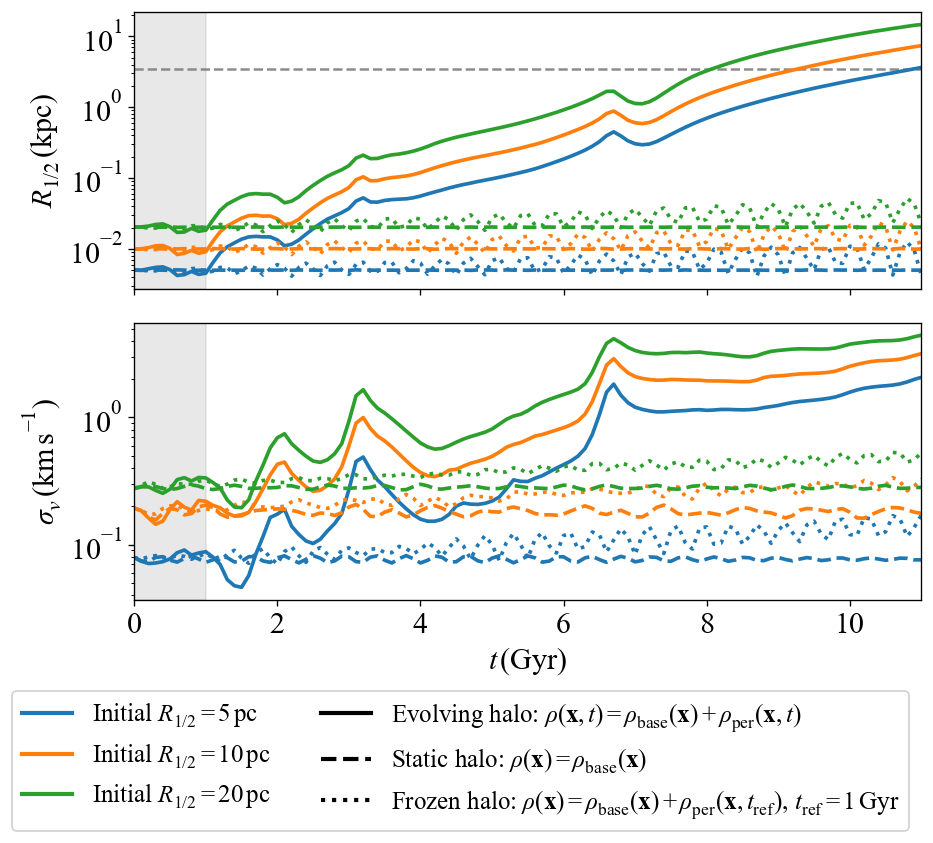

In [4]:
# Compare half-light radius and velocity dispersion with the fiducial evolving run.
m_a = 1.0e-22
halo_mass = 1.0e9
scale_radius = 10.0
alpha = 1.0 / 3.0
time_min_gyr, time_max_gyr = 0.0, 11.0
potential_step_gyr = 0.1
ramp_end_gyr = 1.0
seed = 0

r_c = 1.6 * (m_a / 1.0e-22) ** -1 * (halo_mass / 1.0e9) ** (-alpha)
soliton_radius = SOLITON_RADIUS_KPC

with np.load(SOURCE / f'xvta_Ric{LABELS[0]}.npz') as config_data:
    n_time_samples = config_data['xvta'].shape[0]
    n_particles = config_data['xvta'].shape[2]

print('Plot configuration:')
print(f'  FDM particle mass: m_a = {m_a:.2e} eV')
print('  Tracer particle mass: 0 (massless test particles)')
print(f'  Halo mass: M = {halo_mass:.2e} M_sun')
print(f'  NFW scale radius: r_s = {scale_radius:g} kpc')
print(f'  Soliton core scale: r_c = {r_c:.6g} kpc')
print(f'  Plotted soliton radius: r_sol = {soliton_radius:.6g} kpc')
print(f'  Realization seed: {seed}')
print(f'  Number of tracer particles: {n_particles}')
print('  Initial projected half-light radii: 5, 10, 20 pc')
print(f'  Time range: {time_min_gyr:g}-{time_max_gyr:g} Gyr ({n_time_samples} samples)')
print(f'  Potential cadence: {potential_step_gyr:g} Gyr')
print(f'  Ramp-up interval: {time_min_gyr:g}-{ramp_end_gyr:g} Gyr')
print('  Density cases: evolving, static base, frozen at t_ref = 1 Gyr')

fig, ax = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
radius_colors = {'5pc': '#1f77b4', '10pc': '#ff7f0e', '20pc': '#2ca02c'}
density_styles = {'fiducial': '-', 'static_base': '--', 'frozen010': ':'}
summary = []
for label in LABELS:
    color = radius_colors[label]
    for name in ('fiducial', 'static_base', 'frozen010'):
        with np.load(control_paths[(name, label)]) as d:
            t = d['time_gyr'].copy()
            r, s = cluster_diagnostics(d['xvta'])
        if not np.isclose(t[-1], time_max_gyr):
            raise ValueError(f'{name} {label} ends at {t[-1]:g} Gyr, expected {time_max_gyr:g} Gyr')
        ax[0].plot(t, r, color=color, linestyle=density_styles[name], linewidth=2.2)
        ax[1].plot(t, s, color=color, linestyle=density_styles[name], linewidth=2.2)
        summary.append((name, label, float(r[-1]), float(s[-1])))

radius_handles = [
    Line2D([0], [0], color=radius_colors[label], linewidth=2.5,
           label=rf'Initial $R_{{1/2}}={label[:-2]}\,\mathrm{{pc}}$')
    for label in LABELS
]
density_handles = [
    Line2D([0], [0], color='black', linestyle=density_styles['fiducial'], linewidth=2.5,
           label=r'Evolving halo: $\rho(\mathbf{x},t)=\rho_{\mathrm{base}}(\mathbf{x})+\rho_{\mathrm{per}}(\mathbf{x},t)$'),
    Line2D([0], [0], color='black', linestyle=density_styles['static_base'], linewidth=2.5,
           label=r'Static halo: $\rho(\mathbf{x})=\rho_{\mathrm{base}}(\mathbf{x})$'),
    Line2D([0], [0], color='black', linestyle=density_styles['frozen010'], linewidth=2.5,
           label=r'Frozen halo: $\rho(\mathbf{x})=\rho_{\mathrm{base}}(\mathbf{x})+\rho_{\mathrm{per}}(\mathbf{x},t_{\mathrm{ref}})$, $t_{\mathrm{ref}}=1\,\mathrm{Gyr}$'),
]
ax[0].set_ylabel(r"$R_{1/2}\, (\mathrm{kpc})$"); ax[1].set_ylabel(r"$\sigma_v\, (\mathrm{km\,s^{-1}})$"); ax[1].set_xlabel(r"$t\, (\mathrm{Gyr})$")
for a in ax:
    a.set_yscale('log')
    a.set_xlim(time_min_gyr, time_max_gyr)
    a.margins(x=0)
    a.axvspan(time_min_gyr, ramp_end_gyr, color='gray', alpha=0.18, zorder=0)
ax[0].axhline(soliton_radius, color='gray', linestyle='--', linewidth=1.5, alpha=0.9, zorder=1)
legend_handles = radius_handles + density_handles
fig.legend(handles=legend_handles, loc='lower center', bbox_to_anchor=(0.5, -0.01),
           ncol=2, frameon=True, framealpha=0.9, fontsize=15)
fig.subplots_adjust(left=0.16, right=0.98, bottom=0.28, top=0.98,
                    hspace=0.12)
fig.savefig(FIGURES_DIR / 'controls_tests.png', dpi=300, bbox_inches='tight')
print('control final values:')
for row in summary: print('%-12s %-4s R=%.5g sigma=%.5g' % row)

## 2. Full-orbit spatial representation convergence

Rebuild every potential snapshot at different radial grid sizes and angular orders, then evolve all three stellar initial conditions through the resulting time-dependent potentials. Colors encode the initial $R_{1/2}$ and line styles encode the numerical representation parameter.

N_r= 25, R_ic=5pc: final R=3.64732, sigma=2.06698
N_r= 25, R_ic=10pc: final R=7.40504, sigma=3.17262
N_r= 25, R_ic=20pc: final R=14.7369, sigma=4.43491
N_r= 50, R_ic=5pc: final R=3.58973, sigma=2.09527
N_r= 50, R_ic=10pc: final R=7.38151, sigma=3.21833
N_r= 50, R_ic=20pc: final R=14.6502, sigma=4.45622
N_r=100, R_ic=5pc: final R=3.60994, sigma=2.09894
N_r=100, R_ic=10pc: final R=7.3924, sigma=3.22735
N_r=100, R_ic=20pc: final R=14.6605, sigma=4.45922
Plot: radial_grid_full_orbit_tests.png
  FDM particle mass: m_a = 1.00e-22 eV
  Tracer particle mass: 0 (massless test particles)
  Halo mass: M = 1.00e+09 M_sun
  Number of tracer particles: 10000
  Initial projected half-light radii: 5, 10, 20 pc
  Evolution interval: 0-11 Gyr
  Test parameters:
    Radial grid: $N_r=25$
    Radial grid: $N_r=50$
    Radial grid: $N_r=100$


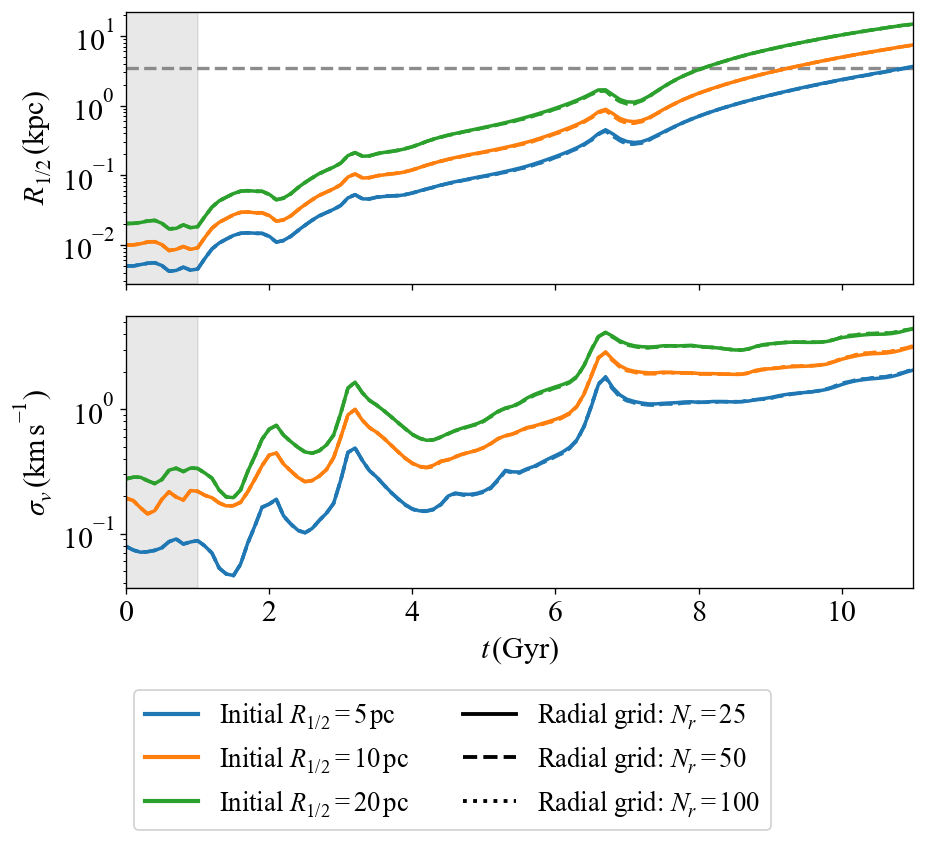

(<Figure size 960x840 with 2 Axes>,
 array([<Axes: ylabel='$R_{1/2}\\, (\\mathrm{kpc})$'>,
        <Axes: xlabel='$t\\, (\\mathrm{Gyr})$', ylabel='$\\sigma_v\\, (\\mathrm{km\\,s^{-1}})$'>],
       dtype=object))

In [5]:
RADIAL_FULL_GRIDS = (25, 50, 100)
radial_masters, radial_outputs = run_radial_grid_orbit_convergence(
    SOURCE, OUTPUT, radial_grids=RADIAL_FULL_GRIDS, labels=LABELS,
    lmax=20, t_step_gyr=0.1, timesteps=110, trajsize=1000,
    force_rebuild=FORCE_RERUN, force_rerun=FORCE_RERUN,
)
radial_results = {
    (grid_size, label): load_evolution(radial_outputs[(grid_size, label)])
    for grid_size in RADIAL_FULL_GRIDS for label in LABELS
}
for grid_size in RADIAL_FULL_GRIDS:
    for label in LABELS:
        _, radius, sigma = radial_results[(grid_size, label)]
        print(f'N_r={grid_size:3d}, R_ic={label}: final R={radius[-1]:.6g}, '
              f'sigma={sigma[-1]:.6g}')
plot_evolution_comparison(
    radial_results, RADIAL_FULL_GRIDS,
    {value: rf'Radial grid: $N_r={value}$' for value in RADIAL_FULL_GRIDS},
    OUTPUT / 'radial_grid_full_orbit_tests.png',
    line_styles={25: '-', 50: '--', 100: ':'},
)


### Full-orbit angular-order convergence

At fixed radial grid $N_r=100$, rebuild the evolving potential for
$l_{\max}=8,12,16,20,23$ and evolve all three initial tracer sizes from
0 to 11 Gyr. This is independent of the radial-resolution cell above.


lmax= 8, R_ic=5pc: final R=4.36363, sigma=2.63354
lmax= 8, R_ic=10pc: final R=8.62545, sigma=3.75394
lmax= 8, R_ic=20pc: final R=15.1503, sigma=4.86419
lmax=12, R_ic=5pc: final R=3.67629, sigma=2.15316
lmax=12, R_ic=10pc: final R=7.5225, sigma=3.28777
lmax=12, R_ic=20pc: final R=14.8288, sigma=4.50721
lmax=16, R_ic=5pc: final R=3.54349, sigma=2.04687
lmax=16, R_ic=10pc: final R=7.3111, sigma=3.16287
lmax=16, R_ic=20pc: final R=14.5959, sigma=4.41003
lmax=20, R_ic=5pc: final R=3.60994, sigma=2.09894
lmax=20, R_ic=10pc: final R=7.3924, sigma=3.22735
lmax=20, R_ic=20pc: final R=14.6605, sigma=4.45922
lmax=23, R_ic=5pc: final R=3.6109, sigma=2.09331
lmax=23, R_ic=10pc: final R=7.37638, sigma=3.21191
lmax=23, R_ic=20pc: final R=14.6305, sigma=4.44932
Plot: angular_order_full_orbit_tests.png
  FDM particle mass: m_a = 1.00e-22 eV
  Tracer particle mass: 0 (massless test particles)
  Halo mass: M = 1.00e+09 M_sun
  Number of tracer particles: 10000
  Initial projected half-light radii: 5, 10,

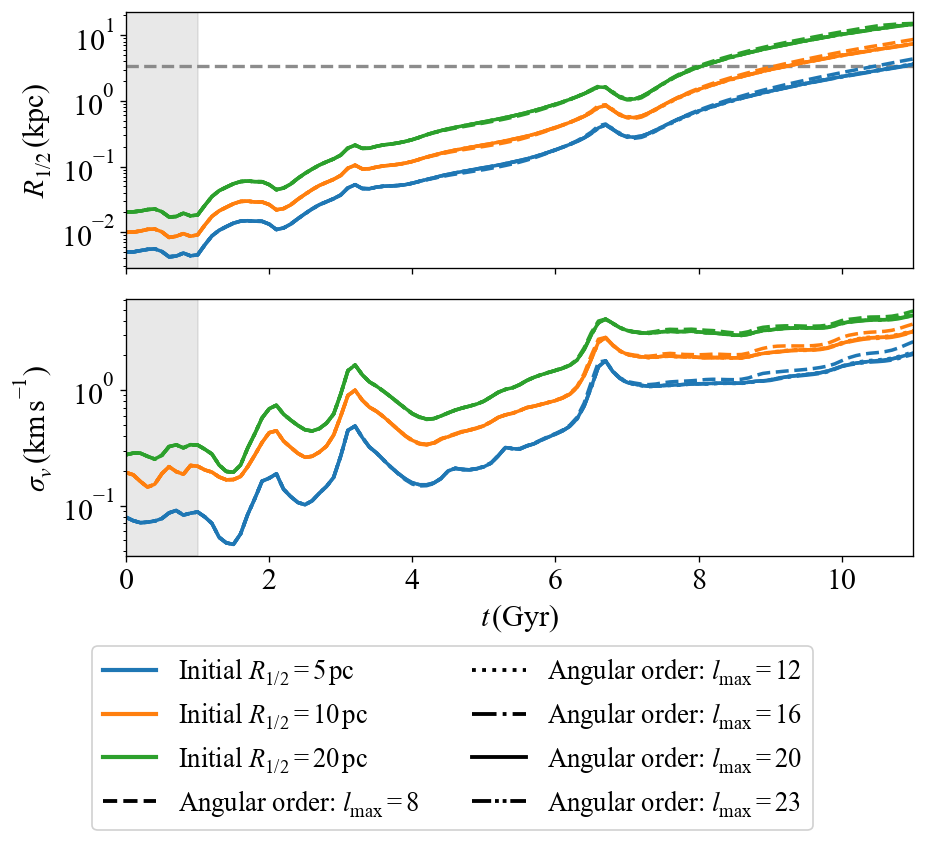

(<Figure size 960x840 with 2 Axes>,
 array([<Axes: ylabel='$R_{1/2}\\, (\\mathrm{kpc})$'>,
        <Axes: xlabel='$t\\, (\\mathrm{Gyr})$', ylabel='$\\sigma_v\\, (\\mathrm{km\\,s^{-1}})$'>],
       dtype=object))

In [6]:
ANGULAR_ORDERS = (8, 12, 16, 20, 23)
angular_masters, angular_outputs = run_angular_order_orbit_convergence(
    SOURCE, OUTPUT, angular_orders=ANGULAR_ORDERS, labels=LABELS,
    radial_grid=100, t_step_gyr=0.1, timesteps=110, trajsize=1000,
    force_rebuild=FORCE_RERUN, force_rerun=FORCE_RERUN,
)
angular_results = {
    (lmax, label): load_evolution(angular_outputs[(lmax, label)])
    for lmax in ANGULAR_ORDERS for label in LABELS
}
for lmax in ANGULAR_ORDERS:
    for label in LABELS:
        _, radius, sigma = angular_results[(lmax, label)]
        print(f'lmax={lmax:2d}, R_ic={label}: final R={radius[-1]:.6g}, '
              f'sigma={sigma[-1]:.6g}')
plot_evolution_comparison(
    angular_results, ANGULAR_ORDERS,
    {value: rf'Angular order: $L_{{\max}}={value}$' for value in ANGULAR_ORDERS},
    OUTPUT / 'angular_order_full_orbit_tests.png',
    line_styles={8: '--', 12: ':', 16: '-.', 20: '-',
                 23: (0, (5, 1, 1, 1, 1, 1))},
)


### Temporal sensitivity

The temporal test deliberately removes every second or third snapshot from the evolving master and compares linear with spline interpolation at the fiducial 0.1-Gyr cadence.

temporal stride 2 median/p90/max [0.02020789 0.10967412 0.39144248]
temporal stride 3 median/p90/max [0.04597296 0.23760731 3.32387969]
linear vs spline median/p90/max [0.05482984 0.12008781 0.27512201]
Plot: temporal_orbit_outcomes_tests.png
  FDM particle mass: m_a = 1.00e-22 eV
  Tracer particle mass: 0 (massless test particles)
  Halo mass: M = 1.00e+09 M_sun
  Number of tracer particles: 10000
  Initial projected half-light radii: 5, 10, 20 pc
  Evolution interval: 0-11 Gyr
  Test parameters:
    Linear interpolation, 0.1 Gyr cadence
    Spline interpolation, 0.1 Gyr cadence
    Linear interpolation, 0.2 Gyr cadence


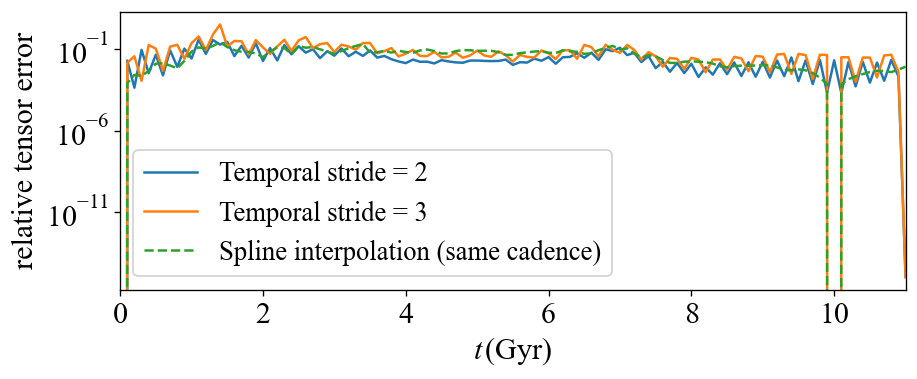

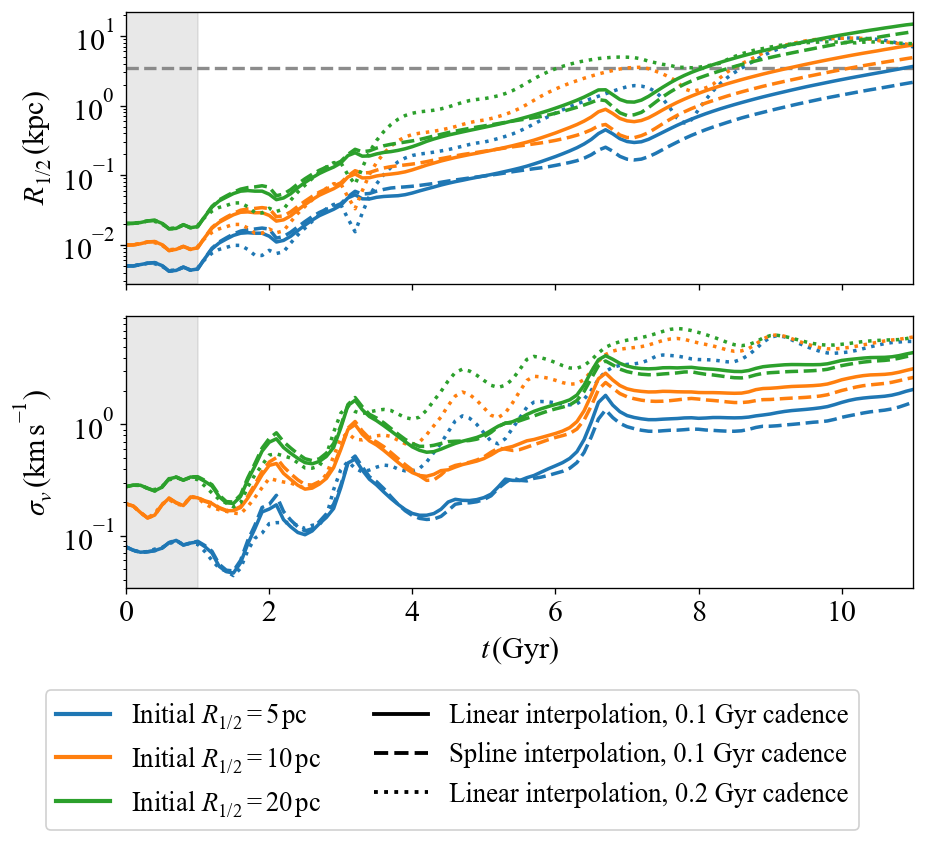

(<Figure size 960x840 with 2 Axes>,
 array([<Axes: ylabel='$R_{1/2}\\, (\\mathrm{kpc})$'>,
        <Axes: xlabel='$t\\, (\\mathrm{Gyr})$', ylabel='$\\sigma_v\\, (\\mathrm{km\\,s^{-1}})$'>],
       dtype=object))

In [7]:
temporal_file = temporal_coarsening_test(
    fiducial_pot, SOURCE, OUTPUT, tidal_centers, tidal_t)
with np.load(temporal_file) as tm:
    reference = tm['reference_tensors']
    tm_err = (np.linalg.norm(tm['coarse_tensors'] - reference, axis=(2, 3)) /
              np.maximum(np.linalg.norm(reference, axis=(1, 2)), 1e-30))
    spline_err = (np.linalg.norm(tm['spline_tensors'] - reference, axis=(1, 2)) /
                  np.maximum(np.linalg.norm(reference, axis=(1, 2)), 1e-30))
    temporal_strides = tm['strides'].copy()

plt.figure(figsize=(8, 3.5))
for stride, error in zip(temporal_strides, tm_err):
    plt.plot(tidal_t, error, label=f'Temporal stride = {stride}')
plt.plot(tidal_t, spline_err, '--', label='Spline interpolation (same cadence)')
plt.yscale('log')
plt.xlim(0, 11)
plt.margins(x=0)
plt.xlabel(r'$t\, (\mathrm{Gyr})$')
plt.ylabel('relative tensor error')
plt.legend(loc='best', frameon=True, framealpha=0.9, fontsize=16)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'temporal_convergence_tests.png', dpi=300)
for stride, error in zip(temporal_strides, tm_err):
    print('temporal stride', stride, 'median/p90/max',
          np.percentile(error, [50, 90, 100]))
print('linear vs spline median/p90/max',
      np.percentile(spline_err, [50, 90, 100]))

# Propagate both temporal alternatives through the full particle evolution.
temporal_potentials = {
    'fiducial': fiducial_pot,
    'spline': ag.Potential(str(OUTPUT / 'evolving_spline.ini')),
    'stride2': ag.Potential(str(OUTPUT / 'evolving_stride2.ini')),
}
temporal_paths = {}
for label in LABELS:
    temporal_paths[('fiducial', label)] = control_paths[('fiducial', label)]
    with np.load(SOURCE / f'xvta_Ric{label}.npz') as data:
        initial_conditions = data['xvta'][0].T.copy()
    for name in ('spline', 'stride2'):
        output_path = OUTPUT / f'xvta_{name}_Ric{label}.npz'
        if FORCE_RERUN and output_path.exists():
            output_path.unlink()
        temporal_paths[(name, label)] = integrate_control(
            temporal_potentials[name], initial_conditions, output_path,
            t_step_gyr=0.1, timesteps=110, trajsize=1000)
TEMPORAL_CASES = ('fiducial', 'spline', 'stride2')
temporal_results = {
    (name, label): load_evolution(temporal_paths[(name, label)])
    for name in TEMPORAL_CASES for label in LABELS
}
plot_evolution_comparison(
    temporal_results, TEMPORAL_CASES,
    {
        'fiducial': 'Linear interpolation, 0.1 Gyr cadence',
        'spline': 'Spline interpolation, 0.1 Gyr cadence',
        'stride2': 'Linear interpolation, 0.2 Gyr cadence',
    },
    OUTPUT / 'temporal_orbit_outcomes_tests.png',
)


## 3. Absolute force accuracy at the evolved particle positions

The production force is compared with a higher-resolution reference Multipole representation built from the same density snapshots. We evaluate both accelerations at the actual fiducial particle positions and report the relative absolute error $|\mathbf a_{\rm prod}-\mathbf a_{\rm ref}|/|\mathbf a_{\rm ref}|$. This directly tests the force used to evolve the tracers; it does not test the tidal-tensor finite-difference approximation.


In [ ]:
# Compare the fiducial force with an N_r=100, l_max=23 reference at every snapshot.
force_sample_indices = np.arange(110, dtype=int)
with np.load(SOURCE / f'xvta_Ric{LABELS[0]}.npz') as fiducial_data:
    fiducial_positions = fiducial_data['xvta'][:, :3, :]
    fiducial_times = np.arange(fiducial_positions.shape[0], dtype=float) * 0.1
reference_paths = {}
for index in force_sample_indices:
    reference_path = OUTPUT / 'potentials' / f'force_reference_l23_r100_t{index:03d}.ini'
    build_static_potential(
        density_paths_for_snapshot(SOURCE, int(index)), reference_path,
        lmax=23, grid_size_r=100)
    reference_paths[int(index)] = reference_path
force_accuracy_file = absolute_force_accuracy_test(
    fiducial_pot, reference_paths, fiducial_positions, fiducial_times,
    OUTPUT / 'absolute_force_accuracy_l23_r100.npz',
    sample_indices=force_sample_indices)
with np.load(force_accuracy_file) as force_data:
    force_times = force_data['times_gyr'].copy()
    force_median = force_data['median_relative_error'].copy()
    force_p90 = force_data['p90_relative_error'].copy()
    force_max = force_data['max_relative_error'].copy()
plt.rcParams.update({'font.size': 13, 'axes.labelsize': 15,
                     'legend.fontsize': 11, 'xtick.labelsize': 12,
                     'ytick.labelsize': 12})
plt.figure(figsize=(7, 4))
plt.semilogy(force_times, force_median, '-', label='median')
plt.semilogy(force_times, force_p90, '--', label='90th percentile')
plt.semilogy(force_times, force_max, ':', label='maximum')
plt.xlabel(r'$t\, (\mathrm{Gyr})$')
plt.ylabel(r'$|a_{\rm prod}-a_{\rm ref}|/|a_{\rm ref}|$')
plt.legend(loc='best', frameon=True, framealpha=0.9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'force_accuracy_tests.png', dpi=300)
print('median absolute force error: min/max =', force_median.min(), force_median.max())
print('90th-percentile absolute force error: min/max =', force_p90.min(), force_p90.max())
print('maximum absolute force error: min/max =', force_max.min(), force_max.max())


## 4. Existing eigenmode-truncation sensitivity

The repository contains cached $R_{1/2}$ results for `Nmax2` and `Nmax3`, but not the corresponding raw potential snapshots. We therefore report the outcome sensitivity here, while explicitly not claiming a new $T_{ij}$ convergence measurement for those truncations.

Plot: nmax_outcome_tests.png
  FDM particle mass: m_a = 1.00e-22 eV
  Tracer particle mass: 0 (massless test particles)
  Halo mass: M = 1.00e+09 M_sun
  Number of tracer particles: 10000
  Initial projected half-light radii: 5, 10, 20 pc
  Evolution interval: 0-11 Gyr
  Test parameters:
    Fiducial eigenmode truncation
    Eigenmode truncation: $N_{\max}=2$
    Eigenmode truncation: $N_{\max}=3$


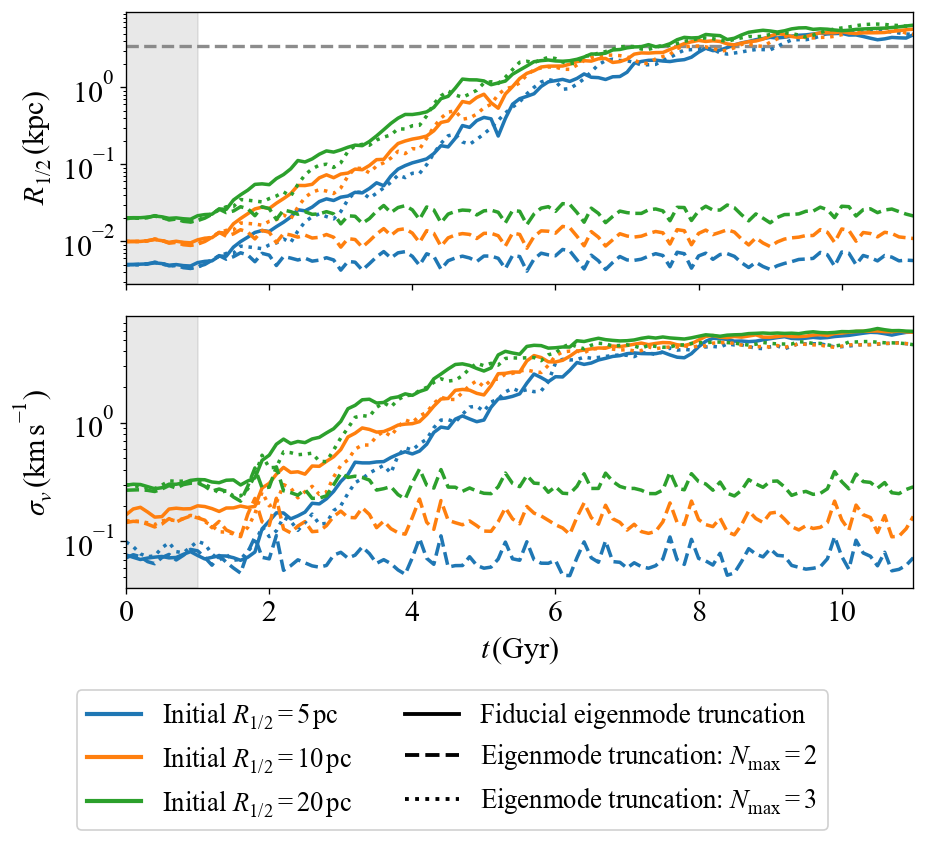

Nmax comparison uses the median across available realizations; raw Nmax potential snapshots are unavailable, so this is outcome-only.


In [10]:
cases = {
    'full': PROJECT / 'RSigma' / 'ma1.0e-22M1.0e+09ts0.1rres512',
    'Nmax2': PROJECT / 'RSigma' / 'ma1.0e-22M1.0e+09ts0.1rres512_Nmax2',
    'Nmax3': PROJECT / 'RSigma' / 'ma1.0e-22M1.0e+09ts0.1rres512_Nmax3',
}
nmax_results = {}
for case, root in cases.items():
    for label in LABELS:
        radius_series, sigma_series, time_series = [], [], []
        for seed_dir in sorted(Path(root).glob('s*')):
            path = seed_dir / f'xvta_Ric{label}.npz'
            if not path.exists():
                continue
            with np.load(path) as data:
                if 'R_half' in data and 'sigma_v' in data:
                    radius = data['R_half'].copy()
                    sigma = data['sigma_v'].copy()
                    time_gyr = data['t_vals'].copy()
                else:
                    radius, sigma = cluster_diagnostics(data['xvta'])
                    if 'time_gyr' in data:
                        time_gyr = data['time_gyr'].copy()
                    else:
                        time_gyr = np.linspace(0.0, 11.0, len(radius))
            if not (np.isclose(time_gyr[0], 0) and np.isclose(time_gyr[-1], 11)):
                raise ValueError(f'{path} does not span 0-11 Gyr')
            radius_series.append(radius)
            sigma_series.append(sigma)
            time_series.append(time_gyr)
        if not radius_series:
            raise FileNotFoundError(f'No {case}, {label} evolution files under {root}')
        if not all(np.allclose(time_series[0], time) for time in time_series[1:]):
            raise ValueError(f'Inconsistent time grids for {case}, {label}')
        nmax_results[(case, label)] = (
            time_series[0], np.median(radius_series, axis=0),
            np.median(sigma_series, axis=0))

NMAX_CASES = tuple(cases)
plot_evolution_comparison(
    nmax_results, NMAX_CASES,
    {
        'full': r'Fiducial eigenmode truncation',
        'Nmax2': r'Eigenmode truncation: $N_{\max}=2$',
        'Nmax3': r'Eigenmode truncation: $N_{\max}=3$',
    },
    OUTPUT / 'nmax_outcome_tests.png',
    line_styles={'full': '-', 'Nmax2': '--', 'Nmax3': ':'},
)
print('Nmax comparison uses the median across available realizations; '
      'raw Nmax potential snapshots are unavailable, so this is outcome-only.')


### Quantitative eigenmode-cutoff comparison

A numerical eigenmode convergence test should hold the random phases, target halo, potential representation, stellar initial conditions, and integration settings fixed, and change only the retained eigenmode cutoff. The following cell quantifies the available `Nmax2`, `Nmax3`, and full outcomes. Because these cached runs do not provide a dense sequence of cutoffs or identical raw potentials, they are a sensitivity test; a strict convergence claim requires regenerating the same seed at successively larger cutoffs until the changes in both diagnostics fall below a stated tolerance.


In [11]:
for label in LABELS:
    _, radius_ref, sigma_ref = nmax_results[('full', label)]
    print(f'R_ic={label}')
    for case in ('Nmax2', 'Nmax3'):
        _, radius, sigma = nmax_results[(case, label)]
        radius_rel = np.abs(radius - radius_ref) / np.maximum(radius_ref, 1e-30)
        sigma_rel = np.abs(sigma - sigma_ref) / np.maximum(sigma_ref, 1e-30)
        print(case, 'final/max relative differences in R_half:',
              radius_rel[-1], np.max(radius_rel),
              '; sigma_v:', sigma_rel[-1], np.max(sigma_rel))


R_ic=5pc
Nmax2 final/max relative differences in R_half: 0.9988306578712002 0.9990478384087199 ; sigma_v: 0.9875158347686347 0.9897627203242803
Nmax3 final/max relative differences in R_half: 0.011340169743066866 0.7581631317254109 ; sigma_v: 0.21317856483358769 0.4093599234592367
R_ic=10pc
Nmax2 final/max relative differences in R_half: 0.9980917565335469 0.9981557999366308 ; sigma_v: 0.9721008869811036 0.9814591272239124
Nmax3 final/max relative differences in R_half: 0.14127021683018987 0.5307187148073418 ; sigma_v: 0.20176958087991076 0.4506613523276289
R_ic=20pc
Nmax2 final/max relative differences in R_half: 0.9966715331184439 0.9967785429803607 ; sigma_v: 0.9512047105717132 0.9579213760459321
Nmax3 final/max relative differences in R_half: 0.0311560201932787 0.5577727781170876 ; sigma_v: 0.22854423411827324 0.4277649261040286


### Same-seed eigenmode-number convergence

This is the strict test described above. It reconstructs seed 0 once, retains modes with $n_{\mathrm{principal}}\equiv n+\ell+1$ up to 5, 9, 13, 17, or 21, rebuilds every 0.1-Gyr potential snapshot, and evolves the identical stellar phase-space realization. Successive curves should approach the cutoff-21 result. Set `FORCE_EIGENMODE_RERUN=True` only when the cached sequences must be rebuilt.


Checking eigenmode cutoff 5; existing files are reused.
  cache hit: xvta_eigenmode_npc5_Ric5pc.npz
  cache hit: xvta_eigenmode_npc5_Ric10pc.npz
  cache hit: xvta_eigenmode_npc5_Ric20pc.npz
Checking eigenmode cutoff 9; existing files are reused.
  cache hit: xvta_eigenmode_npc9_Ric5pc.npz
  cache hit: xvta_eigenmode_npc9_Ric10pc.npz
  cache hit: xvta_eigenmode_npc9_Ric20pc.npz
Checking eigenmode cutoff 13; existing files are reused.
  cache hit: xvta_eigenmode_npc13_Ric5pc.npz
  cache hit: xvta_eigenmode_npc13_Ric10pc.npz
  cache hit: xvta_eigenmode_npc13_Ric20pc.npz
Checking eigenmode cutoff 17; existing files are reused.
  cache hit: xvta_eigenmode_npc17_Ric5pc.npz


10000 orbits complete (67.36 orbits/s)                 
10000 orbits complete (68.82 orbits/s)                 


Checking eigenmode cutoff 21; existing files are reused.


10000 orbits complete (68.96 orbits/s)                 
10000 orbits complete (69.04 orbits/s)                 
10000 orbits complete (69.01 orbits/s)                 


Plot: same_seed_eigenmode_convergence_tests.png
  FDM particle mass: m_a = 1.00e-22 eV
  Tracer particle mass: 0 (massless test particles)
  Halo mass: M = 1.00e+09 M_sun
  Number of tracer particles: 10000
  Initial projected half-light radii: 5, 10, 20 pc
  Evolution interval: 0-11 Gyr
  Test parameters:
    principal cutoff = 5
    principal cutoff = 9
    principal cutoff = 13
    principal cutoff = 17
    principal cutoff = 21


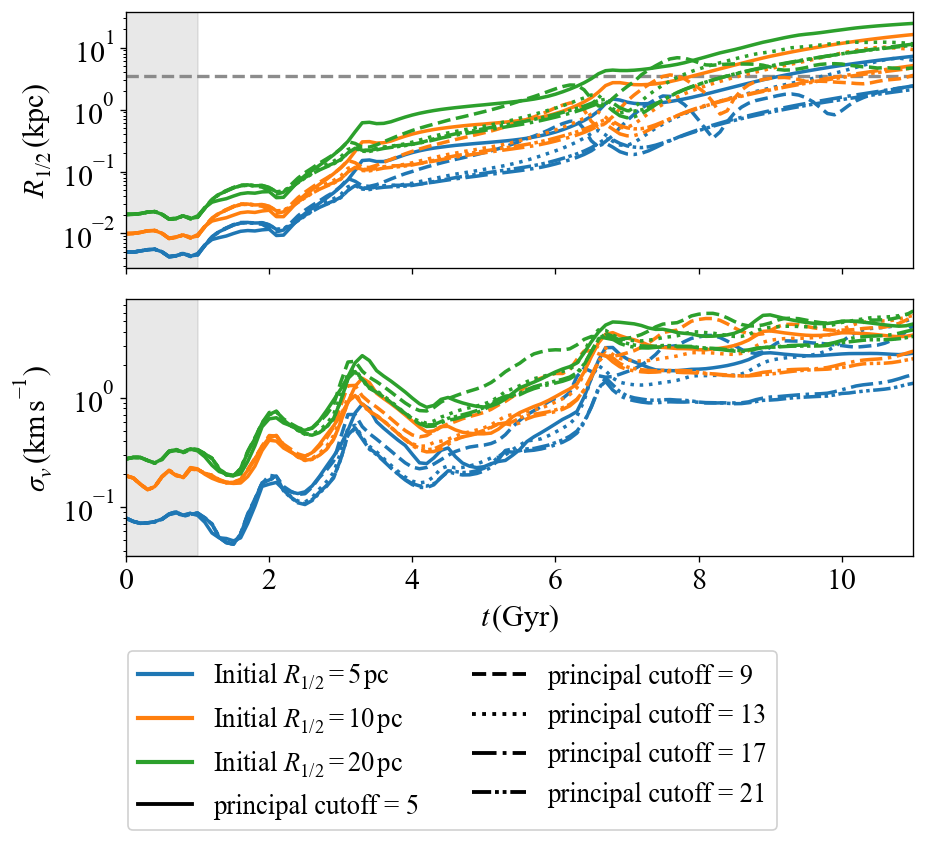

5pc 5 final relative differences from cutoff 21: 2.4274954870787955 0.8872508593207564
5pc 9 final relative differences from cutoff 21: 0.13584245970333667 2.4141210277766256
5pc 13 final relative differences from cutoff 21: 1.933858417633174 2.922895877403023
5pc 17 final relative differences from cutoff 21: 0.1414935740692497 0.2000107539804452
10pc 5 final relative differences from cutoff 21: 2.4740591981006683 0.6461247487479864
10pc 9 final relative differences from cutoff 21: 0.23664962369847217 1.5053781851221406
10pc 13 final relative differences from cutoff 21: 0.9845831972062786 1.4906796346949827
10pc 17 final relative differences from cutoff 21: 0.09525914939773611 0.1737450815410929
20pc 5 final relative differences from cutoff 21: 1.2502568489974897 0.2995967848284689
20pc 9 final relative differences from cutoff 21: 0.5703375324210558 0.7082721257400764
20pc 13 final relative differences from cutoff 21: 0.05420027975073772 0.6232519121693393
20pc 17 final relative differ

In [12]:
EIGENMODE_CUTOFFS = (5, 9, 13, 17, 21)
FORCE_EIGENMODE_RERUN = False
eigenmode_outputs = {}
for cutoff in EIGENMODE_CUTOFFS:
    print(f'Checking eigenmode cutoff {cutoff}; existing files are reused.', flush=True)
    master, _ = generate_true_fine_potentials(
        SOURCE, OUTPUT, cadence_gyr=0.1, principal_cutoff=cutoff,
        force_rerun=FORCE_EIGENMODE_RERUN)
    cutoff_potential = ag.Potential(str(master))
    for label in LABELS:
        with np.load(SOURCE / f'xvta_Ric{label}.npz') as data:
            identical_ic = data['xvta'][0].T.copy()
        output_path = OUTPUT / f'xvta_eigenmode_npc{cutoff}_Ric{label}.npz'
        if output_path.exists() and not FORCE_EIGENMODE_RERUN:
            print(f'  cache hit: {output_path.name}', flush=True)
        if FORCE_EIGENMODE_RERUN and output_path.exists():
            output_path.unlink()
        eigenmode_outputs[(cutoff, label)] = integrate_control(
            cutoff_potential, identical_ic, output_path,
            t_step_gyr=0.1, timesteps=110, trajsize=1000)
eigenmode_results = {
    key: load_evolution(path) for key, path in eigenmode_outputs.items()
}
plot_evolution_comparison(
    eigenmode_results, EIGENMODE_CUTOFFS,
    {value: rf'$n_{{\mathrm{{principal}}}}\leq {value}$' for value in EIGENMODE_CUTOFFS},
    OUTPUT / 'same_seed_eigenmode_convergence_tests.png',
    line_styles={5: '--', 9: ':', 13: '-.',
                 17: (0, (5, 1, 1, 1, 1, 1)), 21: '-'},
)
reference_cutoff = max(EIGENMODE_CUTOFFS)
for label in LABELS:
    _, radius_ref, sigma_ref = eigenmode_results[(reference_cutoff, label)]
    for cutoff in EIGENMODE_CUTOFFS[:-1]:
        _, radius, sigma = eigenmode_results[(cutoff, label)]
        print(label, cutoff, 'final relative differences from cutoff 21:',
              abs(radius[-1] - radius_ref[-1]) / radius_ref[-1],
              abs(sigma[-1] - sigma_ref[-1]) / sigma_ref[-1])


## 5. True finer-time potential rerun

The original directory contains only 0.1-Gyr density snapshots and does not save eigenmode coefficients. The next cell reconstructs the same seed-0 modes with the exact `fdm.ipynb` setup, regenerates every density/potential snapshot at `dt = 0.1 / TIME_RESOLUTION_MULTIPLIER` Gyr, validates selected original times against the old force field, and evolves the unchanged 20-pc initial conditions. Set `TIME_RESOLUTION_MULTIPLIER=4` for 0.025 Gyr; `FORCE_FINE_RERUN` controls regeneration.

dt=0.05 Gyr source force differences: [[0.01150974 0.0182936  0.00263296]
 [0.01330388 0.01404199 0.01023473]
 [0.01737687 0.01622939 0.02053421]]
dt=0.1 Gyr source force differences: [[0.01150974 0.0182936  0.00263296]
 [0.01330388 0.01404199 0.01023473]
 [0.01737687 0.01622939 0.02053421]]
dt=0.2 Gyr source force differences: [[0.01150974 0.0182936  0.00263296]
 [0.01330388 0.01404199 0.01023473]
 [0.01737687 0.01622939 0.02053421]]
potential dt=0.05 Gyr, R_ic=5pc: final R=2.92908, sigma=1.93494
potential dt=0.05 Gyr, R_ic=10pc: final R=6.29394, sigma=3.08723
potential dt=0.05 Gyr, R_ic=20pc: final R=13.5109, sigma=4.5334
potential dt=0.1 Gyr, R_ic=5pc: final R=1.62677, sigma=1.05185
potential dt=0.1 Gyr, R_ic=10pc: final R=3.82228, sigma=1.85968
potential dt=0.1 Gyr, R_ic=20pc: final R=9.47196, sigma=3.23216
potential dt=0.2 Gyr, R_ic=5pc: final R=3.70038, sigma=2.4962
potential dt=0.2 Gyr, R_ic=10pc: final R=7.06513, sigma=3.5164
potential dt=0.2 Gyr, R_ic=20pc: final R=11.3628, si

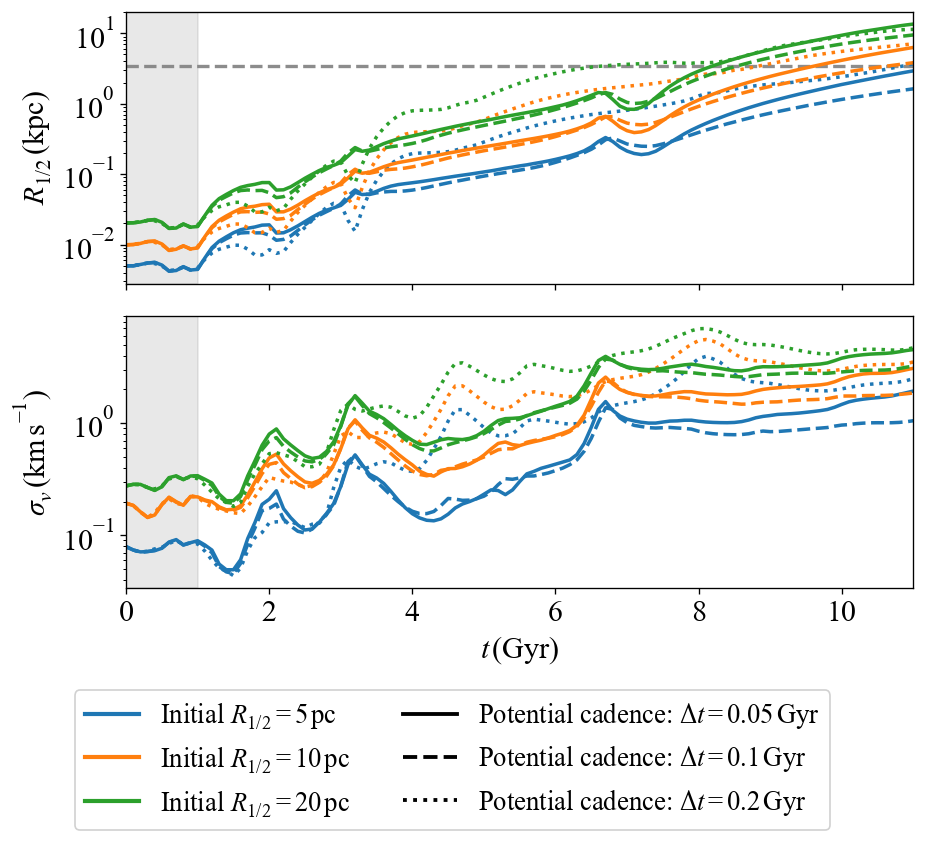

(<Figure size 960x840 with 2 Axes>,
 array([<Axes: ylabel='$R_{1/2}\\, (\\mathrm{kpc})$'>,
        <Axes: xlabel='$t\\, (\\mathrm{Gyr})$', ylabel='$\\sigma_v\\, (\\mathrm{km\\,s^{-1}})$'>],
       dtype=object))

In [13]:
TRUE_FINE_CADENCES = (0.05, 0.1, 0.2)
fine_masters, fine_validations, fine_outputs = {}, {}, {}
fine_initial_conditions = {}
for label in LABELS:
    with np.load(SOURCE / f'xvta_Ric{label}.npz') as data:
        fine_initial_conditions[label] = data['xvta'][0].T.copy()
for cadence_gyr in TRUE_FINE_CADENCES:
    master, validation_path = generate_true_fine_potentials(
        SOURCE, OUTPUT, cadence_gyr=cadence_gyr,
        force_rerun=FORCE_FINE_RERUN)
    fine_masters[cadence_gyr], fine_validations[cadence_gyr] = master, validation_path
    with np.load(validation_path) as validation:
        print(f'dt={cadence_gyr:g} Gyr source force differences:',
              validation['relative_force_error'])
    for label in LABELS:
        cadence_tag = f'dt{cadence_gyr:g}'.replace('.', 'p')
        output_path = OUTPUT / f'xvta_true_{cadence_tag}_Ric{label}.npz'
        if FORCE_FINE_RERUN and output_path.exists():
            output_path.unlink()
        fine_outputs[(cadence_gyr, label)] = integrate_control(
            ag.Potential(str(master)), fine_initial_conditions[label], output_path,
            t_step_gyr=0.1, timesteps=110, trajsize=1000)
fine_results = {
    (cadence_gyr, label): load_evolution(fine_outputs[(cadence_gyr, label)])
    for cadence_gyr in TRUE_FINE_CADENCES for label in LABELS
}
for cadence_gyr in TRUE_FINE_CADENCES:
    for label in LABELS:
        _, radius, sigma = fine_results[(cadence_gyr, label)]
        print(f'potential dt={cadence_gyr:g} Gyr, '
              f'R_ic={label}: final R={radius[-1]:.6g}, sigma={sigma[-1]:.6g}')
plot_evolution_comparison(
    fine_results, TRUE_FINE_CADENCES,
    {value: rf'Potential cadence: $\Delta t={value:g}\,\mathrm{{Gyr}}$'
     for value in TRUE_FINE_CADENCES},
    OUTPUT / 'true_time_resolution_dt0p05_dt0p1_dt0p2_tests.png',
    line_styles={0.05: '--', 0.1: '-', 0.2: ':'},
)


## 6. Agama output-sampling convergence

This test changes Agama's `trajsize` from 1000 to 2000 and 4000. `trajsize` controls regularly spaced output samples, not the adaptive ODE integration steps; all runs retain the default `accuracy=1e-8`. Each trajectory is cached in a separately named NPZ file.

Plot: agama_step_convergence_tests.png
  FDM particle mass: m_a = 1.00e-22 eV
  Tracer particle mass: 0 (massless test particles)
  Halo mass: M = 1.00e+09 M_sun
  Number of tracer particles: 10000
  Initial projected half-light radii: 5, 10, 20 pc
  Evolution interval: 0-11 Gyr
  Test parameters:
    AGAMA trajectory samples: 200
    AGAMA trajectory samples: 500
    AGAMA trajectory samples: 1000
    AGAMA trajectory samples: 2000
    AGAMA trajectory samples: 4000


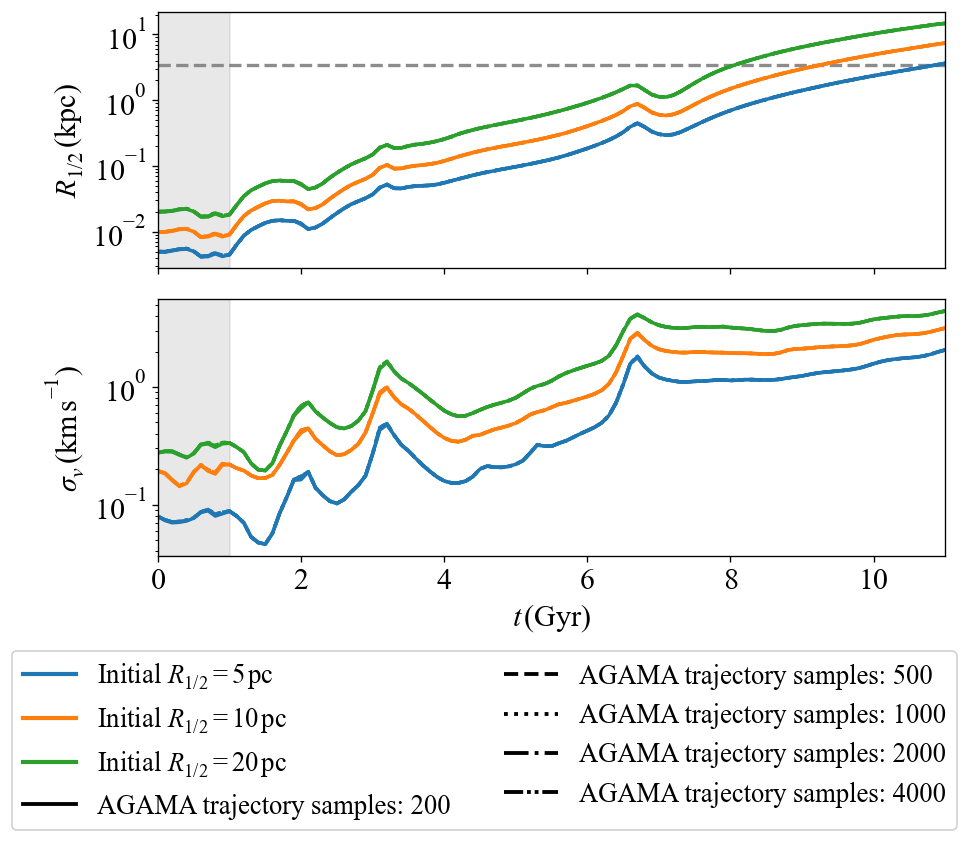

(<Figure size 960x840 with 2 Axes>,
 array([<Axes: ylabel='$R_{1/2}\\, (\\mathrm{kpc})$'>,
        <Axes: xlabel='$t\\, (\\mathrm{Gyr})$', ylabel='$\\sigma_v\\, (\\mathrm{km\\,s^{-1}})$'>],
       dtype=object))

In [14]:
AGAMA_STEPS = (200, 500, 1000, 2000, 4000)
agama_step_outputs = run_agama_step_convergence(
    SOURCE, OUTPUT, labels=LABELS, trajsizes=AGAMA_STEPS,
    force_rerun=FORCE_RERUN)
agama_step_results = {
    (steps, label): load_evolution(path)
    for (steps, label), path in agama_step_outputs.items()
}
plot_evolution_comparison(
    agama_step_results, AGAMA_STEPS,
    {value: f'AGAMA trajectory samples: {value}' for value in AGAMA_STEPS},
    OUTPUT / 'agama_step_convergence_tests.png',
    line_styles={200: '--', 500: ':', 1000: '-', 2000: '-.',
                 4000: (0, (5, 1, 1, 1, 1, 1))},
)


## 7. Agama integration-accuracy convergence

This is the actual integration-precision test. It fixes the saved seed-0 halo, the 20-pc initial particle realization, the 11-Gyr evolution interval, and 111 output epochs, while tightening Agama's adaptive ODE tolerance from `1e-8` to `1e-10` and `1e-12`. Cache names and metadata record the requested accuracy.

Plot: agama_accuracy_convergence_tests.png
  FDM particle mass: m_a = 1.00e-22 eV
  Tracer particle mass: 0 (massless test particles)
  Halo mass: M = 1.00e+09 M_sun
  Number of tracer particles: 10000
  Initial projected half-light radii: 5, 10, 20 pc
  Evolution interval: 0-11 Gyr
  Test parameters:
    ODE accuracy: $1e-02$
    ODE accuracy: $1e-04$
    ODE accuracy: $1e-08$
    ODE accuracy: $1e-10$
    ODE accuracy: $1e-12$


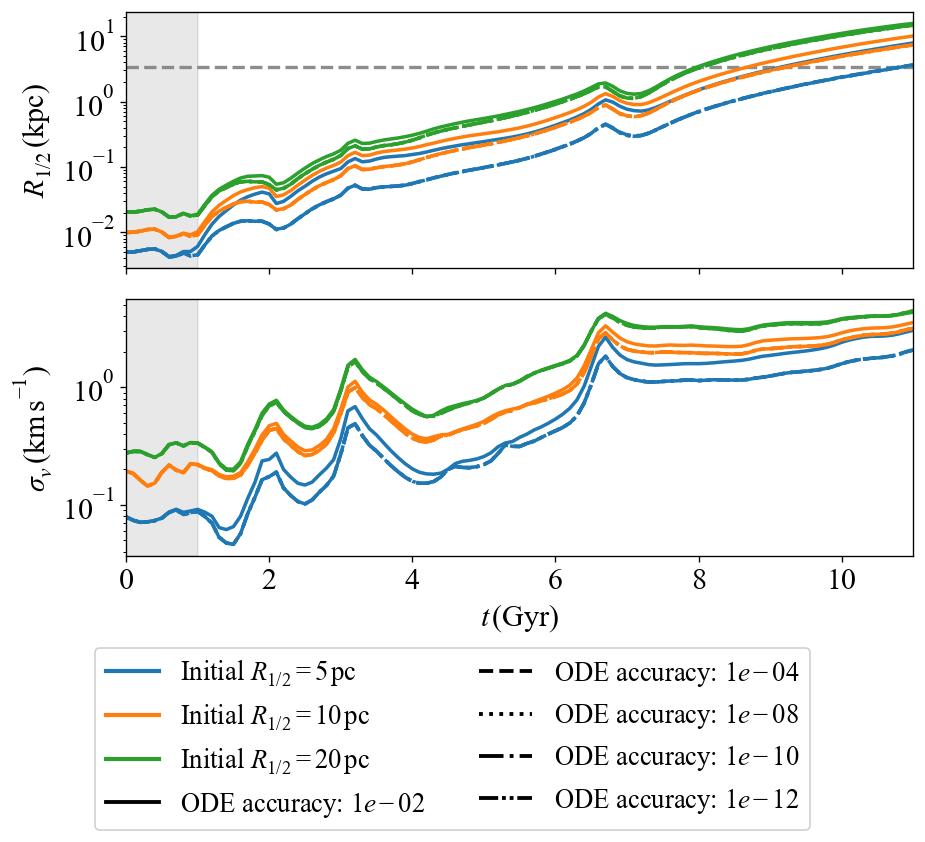

(<Figure size 960x840 with 2 Axes>,
 array([<Axes: ylabel='$R_{1/2}\\, (\\mathrm{kpc})$'>,
        <Axes: xlabel='$t\\, (\\mathrm{Gyr})$', ylabel='$\\sigma_v\\, (\\mathrm{km\\,s^{-1}})$'>],
       dtype=object))

In [15]:
AGAMA_ACCURACIES = (1e-2, 1e-4, 1e-8, 1e-10, 1e-12)
agama_accuracy_outputs = run_agama_accuracy_convergence(
    SOURCE, OUTPUT, labels=LABELS, accuracies=AGAMA_ACCURACIES,
    force_rerun=FORCE_RERUN)
agama_accuracy_results = {
    (accuracy, label): load_evolution(path)
    for (accuracy, label), path in agama_accuracy_outputs.items()
}
plot_evolution_comparison(
    agama_accuracy_results, AGAMA_ACCURACIES,
    {value: rf'ODE accuracy: ${value:.0e}$' for value in AGAMA_ACCURACIES},
    OUTPUT / 'agama_accuracy_convergence_tests.png',
    line_styles={1e-2: '--', 1e-4: ':', 1e-8: '-', 1e-10: '-.',
                 1e-12: (0, (5, 1, 1, 1, 1, 1))},
)


## Conclusions

The notebook now treats radial resolution and angular order as full-orbit
convergence tests. Each test evolves initial projected half-light radii of
5, 10, and 20 pc from 0 to 11 Gyr. Color identifies the initial radius and
line style identifies the numerical parameter. In particular, the angular
test compares complete evolutions at fixed $N_r=100$ for
$l_{\max}=8,12,16,20,23$; no $\Delta T$ proxy is used for its convergence
conclusion.

Static-base, frozen-field, temporal-interpolation, true potential-cadence,
AGAMA trajectory-sampling, integration-accuracy, and eigenmode-truncation
outcomes are presented with the same three-radius convention. The direct
force-derivative test checks AGAMA's Hessian against centred acceleration
differences near the halo centre. The same-seed eigenmode test rebuilds the
full time-dependent potential at five principal-mode cutoffs. AGAMA adaptive
integration sensitivity is tested by varying `accuracy`. The old
cached `Nmax2`/`Nmax3` comparison remains a sensitivity diagnostic and is
not used by itself as evidence of numerical eigenmode convergence.
